In [3]:
""" BLOCK 1 - SAMPLE UNSEEN TEST IMAGES INTO PARQUET """

import os
import glob
import numpy as np
import geopandas as gpd
import pandas as pd
import rasterio
from rasterio.features import geometry_mask
from shapely.geometry import box, mapping
from tqdm import tqdm
import pyarrow.parquet as pq
import pyarrow as pa
from numba import njit

# Numba helpers
SCL_INVALID_CODES = np.array([0, 1, 2, 3, 7, 8, 9, 10], dtype=np.uint8)

@njit(parallel=True, fastmath=True)
def valid_mask_from_scl_numba(scl, nodata_val, invalid_codes):
    mask = np.ones(scl.shape, dtype=np.bool_)
    for i in range(scl.shape[0]):
        for j in range(scl.shape[1]):
            val = scl[i, j]
            if val == nodata_val:
                mask[i, j] = False
                continue
            for code in invalid_codes:
                if val == code:
                    mask[i, j] = False
                    break
    return mask


def sample_valid_pixels(valid_mask, n, seed=None):
    """Fast pixel sampling using NumPy."""
    if seed is not None:
        np.random.seed(seed)
    ys, xs = np.nonzero(valid_mask)
    if len(ys) == 0:
        return np.empty(0, dtype=np.int64), np.empty(0, dtype=np.int64)
    if n >= len(ys):
        return ys, xs
    idx = np.random.choice(len(ys), size=n, replace=False)
    return ys[idx], xs[idx]


def generate_test_parquet(base_dir, study_site, lake_shp, out_test_path, 
                         num_samples_per_lake=5, sentinel_epsg=32606):
    """
    Generate test samples from UNSEEN images in _ICE and _WATER folders.
    """
    
    site_dir = os.path.join(base_dir, study_site)
    class_folders = {
        "ice": os.path.join(site_dir, "_ICE"),
        "water": os.path.join(site_dir, "_WATER"),
    }

    # Build classification table
    records = []
    for label, fdir in class_folders.items():
        for jpg_path in glob.glob(os.path.join(fdir, "*.jpg")):
            scene_name = os.path.basename(jpg_path)
            records.append({"scene_name": scene_name, "class": label})
    
    df_class = pd.DataFrame(records)
    print(f"Found {len(df_class)} unseen test images:")
    print(f"  Ice: {len(df_class[df_class['class']=='ice'])}")
    print(f"  Water: {len(df_class[df_class['class']=='water'])}")

    # Load lakes shapefile
    gdf_lakes = gpd.read_file(lake_shp).to_crs(epsg=sentinel_epsg)

    all_samples = []

    for i, rec in tqdm(df_class.iterrows(), total=len(df_class), desc="Processing test scenes"):
        scene_name = rec["scene_name"]
        label = rec["class"]

        scene_token = scene_name.split("_RGB")[0]
        scene_folder = os.path.join(site_dir, scene_token)

        desired_bands = ["B02", "B03", "B04", "B08", "B11", "B12"]
        band_paths = [os.path.join(scene_folder, f"{b}.tif")
                      for b in desired_bands if os.path.exists(os.path.join(scene_folder, f"{b}.tif"))]

        scl_path = os.path.join(scene_folder, "SCL.tif")

        # Use 10m band as reference
        prefer_10m = [p for p in band_paths if any(b in p for b in ["B02", "B03", "B04", "B08"])]
        ref_band_path = prefer_10m[0] if prefer_10m else band_paths[0]
        with rasterio.open(ref_band_path) as ref_src:
            height, width = ref_src.height, ref_src.width
            transform = ref_src.transform

        # Load all bands with resampling
        band_stack, band_names = [], []
        for bp in band_paths:
            bname = os.path.basename(bp)
            with rasterio.open(bp) as src:
                data = src.read(1, out_shape=(height, width), resampling=rasterio.enums.Resampling.nearest)
            band_stack.append(data)
            band_names.append(os.path.splitext(bname)[0])
        band_stack = np.stack(band_stack)

        # Load SCL mask
        with rasterio.open(scl_path) as srcs:
            scl = srcs.read(1, out_shape=(height, width), resampling=rasterio.enums.Resampling.nearest)
            nodata_val = srcs.nodata if srcs.nodata is not None else 0

        valid_mask = valid_mask_from_scl_numba(scl.astype(np.uint8), np.uint8(nodata_val), SCL_INVALID_CODES)

        # Lake sampling
        raster_bounds = box(*rasterio.transform.array_bounds(height, width, transform))
        lakes_in_scene = gdf_lakes[gdf_lakes.intersects(raster_bounds)]
        if lakes_in_scene.empty:
            continue
        geoms = [mapping(l.geometry.intersection(raster_bounds)) for _, l in lakes_in_scene.iterrows() if not l.geometry.is_empty]
        if not geoms:
            continue
        lake_mask = ~geometry_mask(geoms, transform=transform, invert=True, out_shape=(height, width))

        combined_mask = valid_mask & lake_mask
        total_samples = num_samples_per_lake * len(geoms)
        ys, xs = sample_valid_pixels(combined_mask, total_samples, seed=42)
        if len(ys) == 0:
            continue

        # Create df with band values + SCL
        sample_records = []
        for y, x in zip(ys, xs):
            sample_data = {name: float(band_stack[i, y, x]) for i, name in enumerate(band_names)}
            sample_data["SCL"] = int(scl[y, x])
            sample_data.update({
                "scene": scene_token,
                "label": label,
                "row": int(y),
                "col": int(x)
            })
            sample_records.append(sample_data)
        if sample_records:
            all_samples.append(pd.DataFrame(sample_records))

    # Save to parquet
    df_all = pd.concat(all_samples, ignore_index=True)
    print(f"\nSaving {len(df_all)} test samples to {out_test_path}")
    print(f"  Ice samples: {len(df_all[df_all['label']=='ice'])}")
    print(f"  Water samples: {len(df_all[df_all['label']=='water'])}")

    table = pa.Table.from_pandas(df_all)
    os.makedirs(os.path.dirname(out_test_path), exist_ok=True)
    pq.write_table(table, out_test_path)


# Run test sampling
test_output_path = r"E:\planetscope_lake_ice\Data\Input\Machine Learning - Sentinel Samples for RF\Models\YKD Freezeup\YKD_freezeup_TEST.parquet" # change this

generate_test_parquet(
    base_dir=r"E:\planetscope_lake_ice\Data\Input\Machine Learning - Sentinel Samples for RF",
    study_site="YKD", # change this
    lake_shp=r"E:\planetscope_lake_ice\Data\Input\Study Sites - Manual ALPOD Data\YKD 50x50 km\YKD Lakes from ALPOD Shapefile\YKD_50x50km_lakes.shp", # change this
    out_test_path=test_output_path,
    num_samples_per_lake=5,
    sentinel_epsg=32603 # change this
)

Found 90 unseen test images:
  Ice: 65
  Water: 25


Processing test scenes: 100%|██████████| 90/90 [11:15<00:00,  7.50s/it]



Saving 1092795 test samples to E:\planetscope_lake_ice\Data\Input\Machine Learning - Sentinel Samples for RF\Models\YKD Freezeup\YKD_freezeup_TEST.parquet
  Ice samples: 761985
  Water samples: 330810


Loading trained model...
Model trained on 405995 samples
Training CV accuracy: 0.9668
Training test accuracy: 0.9668

Loading test data...
Test samples: 97360
  Ice: 79875
  Water: 17485

Making predictions...

UNSEEN TEST SET PERFORMANCE

Overall Accuracy: 0.9063

Ice Metrics:
  Precision: 0.9494
  Recall:    0.9357
  F1-Score:  0.9425

Water Metrics:
  Precision: 0.7244
  Recall:    0.7721
  F1-Score:  0.7475

DETAILED CLASSIFICATION REPORT
              precision    recall  f1-score   support

         ice       0.95      0.94      0.94     79875
       water       0.72      0.77      0.75     17485

    accuracy                           0.91     97360
   macro avg       0.84      0.85      0.85     97360
weighted avg       0.91      0.91      0.91     97360


Confusion matrix saved to: E:\planetscope_lake_ice\Data\Input\Machine Learning - Sentinel Samples for RF\Models\YF Freezeup\YF_freezeup_TEST_confusion_matrix.png


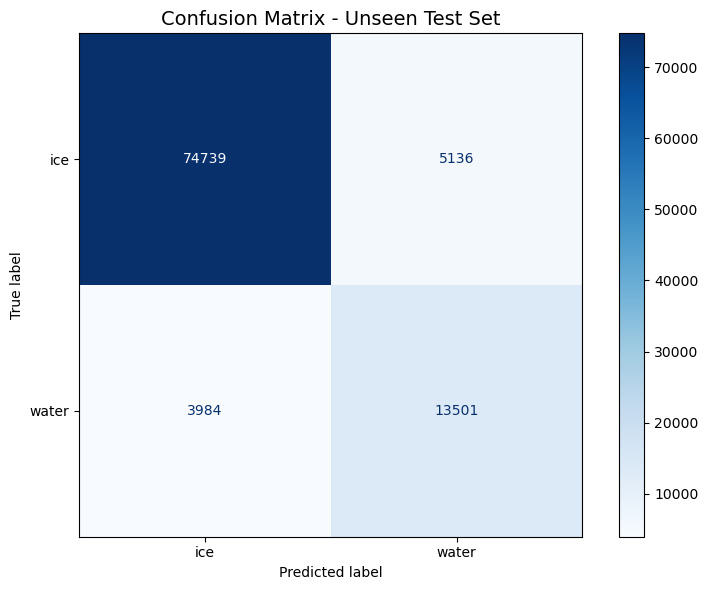


Generating radar plot...
Radar plot saved to: E:\planetscope_lake_ice\Data\Input\Machine Learning - Sentinel Samples for RF\Models\YF Freezeup\YF_freezeup_TEST_radar_plot.png


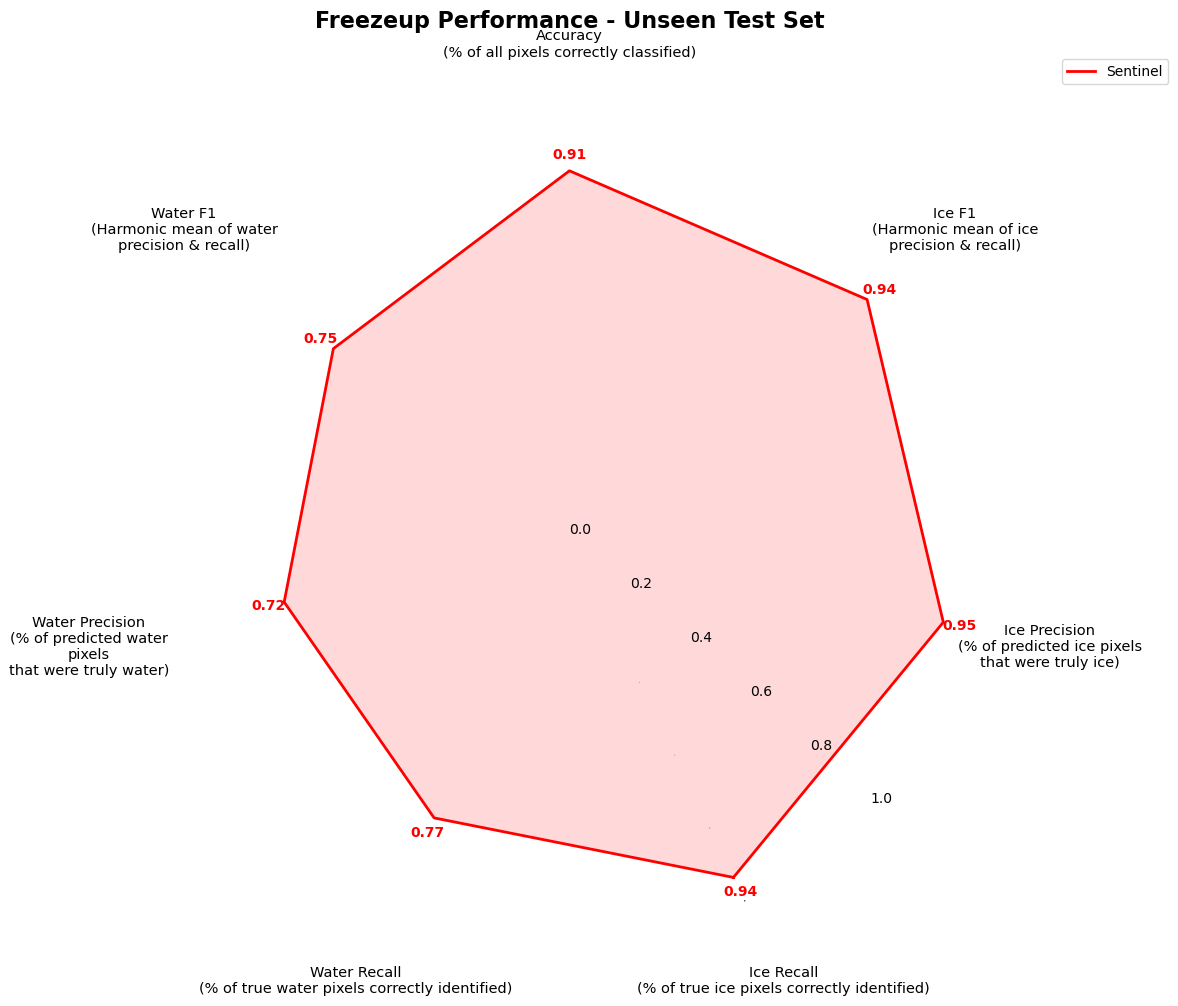

Metrics saved to: E:\planetscope_lake_ice\Data\Input\Machine Learning - Sentinel Samples for RF\Models\YF Freezeup\YF_freezeup_TEST_metrics.csv

EVALUATION COMPLETE


In [6]:
""" BLOCK 2 - EVALUATE MODEL ON UNSEEN TEST DATA """

import pandas as pd
import pyarrow.parquet as pq
import joblib
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay
from sklearn.metrics import precision_recall_fscore_support, accuracy_score

# Paths
model_path = r"E:\planetscope_lake_ice\Data\Input\Machine Learning - Sentinel Samples for RF\Models\Combined Freezeup\Combined_freezeup_RFmodel.joblib"
test_parquet_path = r"E:\planetscope_lake_ice\Data\Input\Machine Learning - Sentinel Samples for RF\Models\YF Freezeup\YF_freezeup_TEST.parquet"

# Load trained model
print("Loading trained model...")
model_package = joblib.load(model_path)
model = model_package["model"]
label_encoder = model_package["label_encoder"]
feature_cols = model_package["feature_columns"]

print(f"Model trained on {model_package['training_samples']} samples")
print(f"Training CV accuracy: {model_package['cv_score']:.4f}")
print(f"Training test accuracy: {model_package['test_accuracy']:.4f}")

# Load test data
print("\nLoading test data...")
df_test = pq.read_table(test_parquet_path).to_pandas()
print(f"Test samples: {len(df_test)}")
print(f"  Ice: {len(df_test[df_test['label']=='ice'])}")
print(f"  Water: {len(df_test[df_test['label']=='water'])}")

# Prepare features
X_test = df_test[feature_cols].astype(float)
y_test = label_encoder.transform(df_test["label"])

# Make predictions
print("\nMaking predictions...")
y_pred = model.predict(X_test)

# Calculate metrics
accuracy = accuracy_score(y_test, y_pred)
precision, recall, f1, support = precision_recall_fscore_support(
    y_test, y_pred, labels=[0, 1], average=None
)

# Assuming label_encoder.classes_ = ['ice', 'water']
# labels=[0, 1] corresponds to ['ice', 'water']
ice_idx = 0
water_idx = 1

print("\n" + "="*60)
print("UNSEEN TEST SET PERFORMANCE")
print("="*60)
print(f"\nOverall Accuracy: {accuracy:.4f}")
print(f"\nIce Metrics:")
print(f"  Precision: {precision[ice_idx]:.4f}")
print(f"  Recall:    {recall[ice_idx]:.4f}")
print(f"  F1-Score:  {f1[ice_idx]:.4f}")
print(f"\nWater Metrics:")
print(f"  Precision: {precision[water_idx]:.4f}")
print(f"  Recall:    {recall[water_idx]:.4f}")
print(f"  F1-Score:  {f1[water_idx]:.4f}")

# Classification report
print("\n" + "="*60)
print("DETAILED CLASSIFICATION REPORT")
print("="*60)
print(classification_report(y_test, y_pred, target_names=label_encoder.classes_))

# Confusion matrix
cm = confusion_matrix(y_test, y_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=label_encoder.classes_)
fig, ax = plt.subplots(figsize=(8, 6))
disp.plot(ax=ax, cmap='Blues', values_format='d')
plt.title('Confusion Matrix - Unseen Test Set', fontsize=14)
plt.tight_layout()
cm_path = test_parquet_path.replace(".parquet", "_confusion_matrix.png")
plt.savefig(cm_path, dpi=150)
print(f"\nConfusion matrix saved to: {cm_path}")
plt.show()

# Create radar plot with Sentinel metrics only
print("\nGenerating radar plot...")

labels_plot = [
    'Ice Recall\n(% of true ice pixels correctly identified)',
    'Ice Precision\n(% of predicted ice pixels\nthat were truly ice)',
    'Ice F1\n(Harmonic mean of ice\nprecision & recall)',
    'Accuracy\n(% of all pixels correctly classified)',
    'Water F1\n(Harmonic mean of water\nprecision & recall)',
    'Water Precision\n(% of predicted water pixels\nthat were truly water)',
    'Water Recall\n(% of true water pixels correctly identified)'
]

# Sentinel metrics from our test
sentinel = [
    recall[ice_idx],      # Ice Recall
    precision[ice_idx],   # Ice Precision
    f1[ice_idx],          # Ice F1
    accuracy,             # Accuracy
    f1[water_idx],        # Water F1
    precision[water_idx], # Water Precision
    recall[water_idx]     # Water Recall
]

# Close the radar plot
sentinel_vals = sentinel + sentinel[:1]
angles = np.linspace(0, 2 * np.pi, len(labels_plot), endpoint=False).tolist()
angles += angles[:1]

# Create plot
fig = plt.figure(figsize=(12, 12))
ax = plt.subplot(111, polar=True)

# Rotate so "Accuracy" sits at the top
rotation = np.pi/2 - angles[3]
ax.set_theta_offset(rotation)

# Plot Sentinel (red)
ax.plot(angles, sentinel_vals, linewidth=2, color='red', label='Sentinel')
ax.fill(angles, sentinel_vals, alpha=0.15, color='red')

# Add values as text
for i, angle in enumerate(angles[:-1]):
    ax.text(angle, sentinel[i] + 0.04, f"{sentinel[i]:.2f}",
            color='red', fontsize=10, ha='center', va='center', weight='bold')

# Remove default tick labels
ax.set_xticks([])

# Add custom labels
label_radius = 1.22
for angle, label in zip(angles[:-1], labels_plot):
    ax.text(angle, label_radius, label,
            fontsize=10.5, ha='center', va='center', wrap=True, linespacing=1.2)

ax.set_ylim(0.0, 1.0)
ax.set_yticks(np.linspace(0, 1, 6))
ax.set_yticklabels([f"{v:.1f}" for v in np.linspace(0, 1, 6)], fontsize=10)

plt.title("Freezeup Performance - Unseen Test Set", 
          fontsize=16, y=1.12, weight='bold')
plt.legend(loc='upper right', bbox_to_anchor=(1.25, 1.1))
plt.tight_layout()

radar_path = test_parquet_path.replace(".parquet", "_radar_plot.png")
plt.savefig(radar_path, dpi=150, bbox_inches='tight')
print(f"Radar plot saved to: {radar_path}")
plt.show()

# Save metrics to CSV
metrics_df = pd.DataFrame({
    'Metric': ['Ice Recall', 'Ice Precision', 'Ice F1', 'Accuracy', 
               'Water F1', 'Water Precision', 'Water Recall'],
    'Value': sentinel
})
csv_path = test_parquet_path.replace(".parquet", "_metrics.csv")
metrics_df.to_csv(csv_path, index=False)
print(f"Metrics saved to: {csv_path}")

print("\n" + "="*60)
print("EVALUATION COMPLETE")
print("="*60)